In [1]:
import pandas as pd
import numpy as np
import re
import os
import pickle
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory, StopWordRemover, ArrayDictionary
from sklearn.feature_extraction.text import TfidfVectorizer

# Load dataset

In [2]:
# Load dataset
df = pd.read_csv("C:/Users/mjova/OneDrive/Documents/kuliah/Skripsi/deteksi_depresi/Data/Processed/Dataset_Full_Metadata.csv")

In [3]:
print(f"Dataset size before filtering: {len(df)}")
df.head()

Dataset size before filtering: 7568


,label,class_name,source_file,tweet,created_at,id_str,username,favorite_count,retweet_count,tweet_url
0,0,Normal,Normal_Hobby_August.csv,sedih bgt aku tuh klo telat olahraga,Sat Aug 30 23:54:28 +0000 2025,1961940615220105339,NaN,0,0,https://x.com/undefined/status/196194061522010...
1,0,Normal,Normal_Hobby_August.csv,kepikiran konser kalo batal antara sedih dan s...,Sat Aug 30 21:46:08 +0000 2025,1961908319049875544,NaN,0,0,https://x.com/undefined/status/196190831904987...
2,0,Normal,Normal_Hobby_August.csv,capek ngantuk tapi dengan tidur aja gw udah ng...,Sat Aug 30 19:16:33 +0000 2025,1961870676341797059,NaN,1,0,https://x.com/undefined/status/196187067634179...
3,0,Normal,Normal_Hobby_August.csv,@gummyglossy iya kan rasanya mau tidur tuh pik...,Sat Aug 30 19:09:27 +0000 2025,1961868889450783173,NaN,0,0,https://x.com/undefined/status/196186888945078...
4,0,Normal,Normal_Hobby_August.csv,- itu karena keren bgt coiii poto mereka berem...,Sat Aug 30 17:53:09 +0000 2025,1961849688040341982,NaN,0,0,https://x.com/undefined/status/196184968804034...


## Ideas for cleaning / filtering
1. remove entries that contain positive, or medical sounding tags
2. remove entries with more than three hashtags, as it may be promotional messages
3. remove entries with at mentions, as it may be promotional messages
4. remove entries with less than x chars / words
5. remove entries containing urls - again as they are likely to be promotional messages

In [7]:
# Function to remove positive or medical-sounding tags
def remove_positive_tags(tweet):
    if isinstance(tweet, str):  # Check if the input is a string
        positive_tags = ['#happy', '#joy', '#wellness', '#cure', '#health', '#healing']
        return not any(tag in tweet for tag in positive_tags)
    return True  # If not a string (e.g., NaN), keep the entry

# Function to remove entries with more than three hashtags
def remove_too_many_hashtags(tweet):
    if isinstance(tweet, str):  # Check if the input is a string
        return tweet.count('#') <= 3
    return True  # If not a string, keep the entry

# Function to remove entries with at mentions
def remove_mentions(tweet):
    if isinstance(tweet, str):  # Check if the input is a string
        return '@' not in tweet
    return True  # If not a string, keep the entry

# Function to remove entries with less than x characters (e.g., 10 characters)
def remove_short_entries(tweet, min_length=10):
    if isinstance(tweet, str):  # Check if the input is a string
        return len(tweet) >= min_length
    return True  # If not a string, keep the entry

# Function to remove entries containing URLs
def remove_urls(tweet):
    if isinstance(tweet, str):  # Check if the input is a string
        return not bool(re.search(r'http[s]?://', tweet))
    return True  # If not a string, keep the entry

# Apply the cleaning functions
df = df[df['tweet'].apply(remove_positive_tags)]
df = df[df['tweet'].apply(remove_too_many_hashtags)]
df = df[df['tweet'].apply(remove_mentions)]
df = df[df['tweet'].apply(lambda x: remove_short_entries(x, min_length=10))]
df = df[df['tweet'].apply(remove_urls)]

In [8]:
# Check dataset size after filtering
print(f"Dataset size after filtering: {len(df)}")

Dataset size after filtering: 5182


In [9]:
df.head()

,label,class_name,source_file,tweet,created_at,id_str,username,favorite_count,retweet_count,tweet_url
0,0,Normal,Normal_Hobby_August.csv,sedih bgt aku tuh klo telat olahraga,Sat Aug 30 23:54:28 +0000 2025,1961940615220105339,NaN,0,0,https://x.com/undefined/status/196194061522010...
1,0,Normal,Normal_Hobby_August.csv,kepikiran konser kalo batal antara sedih dan s...,Sat Aug 30 21:46:08 +0000 2025,1961908319049875544,NaN,0,0,https://x.com/undefined/status/196190831904987...
2,0,Normal,Normal_Hobby_August.csv,capek ngantuk tapi dengan tidur aja gw udah ng...,Sat Aug 30 19:16:33 +0000 2025,1961870676341797059,NaN,1,0,https://x.com/undefined/status/196187067634179...
4,0,Normal,Normal_Hobby_August.csv,- itu karena keren bgt coiii poto mereka berem...,Sat Aug 30 17:53:09 +0000 2025,1961849688040341982,NaN,0,0,https://x.com/undefined/status/196184968804034...
6,0,Normal,Normal_Hobby_August.csv,Pengen nangis cuma bisa ngelike kagak bisa nge...,Sat Aug 30 17:16:34 +0000 2025,1961840482167955914,NaN,0,0,https://x.com/undefined/status/196184048216795...


# Save Dataset for Labelling

In [10]:
df.to_csv('cleaned_tweets_for_labelling.csv', index=False)

# Remove mentions and retweets

In [12]:
# Remove mentions and retweets
def remove_pattern(text, pattern_regex):
    r = re.findall(pattern_regex, text)
    for i in r:
        text = re.sub(i, '', text)
    return text

df['clean_tweet'] = np.vectorize(remove_pattern)(df['tweet'], " *RT* | *@[//w]*")

# Remove symbols
def remove_symbols(text):
    text = ' '.join(re.sub("(@[A-Za-z0-9]+)|([^0-9A-Za-z //t])|(//w+:////////S+)", " ", text).split())
    return text

df['remove_http'] = df['clean_tweet'].apply(lambda x: remove_symbols(x))


# Remove hashtags and numbers

In [13]:
# Remove hashtags and numbers
def remove_hashtags_numbers(tweet):
    tweet = re.sub(r'//$//w*', ' ', tweet)
    tweet = re.sub(r'^RT[//s]+', ' ', tweet)
    tweet = re.sub(r'#', ' ', tweet)
    tweet = re.sub('[0-9]+', ' ', tweet)
    return tweet

df['remove_hashtag'] = df['remove_http'].apply(lambda x: remove_hashtags_numbers(x))

# Remove duplicates

In [14]:
# Remove duplicates
df.drop_duplicates(subset="remove_hashtag", keep='first', inplace=True)

## finding stopwords

In [15]:
from collections import Counter

# Split the text into words (tokenization)
all_words = ' '.join(df['remove_hashtag']).split()

# Count word frequencies
word_counts = Counter(all_words)

# Convert to DataFrame for ranking
word_freq_df = pd.DataFrame(word_counts.items(), columns=['Word', 'Frequency'])
word_freq_df = word_freq_df.sort_values(by='Frequency', ascending=False)

word_freq_df.to_csv('word_frequencies.csv', index=False)

# Display top 10 most frequent words
print(word_freq_df)

                    Word  Frequency
2                    aku       3364
14                   gue       2246
0                  sedih       1750
27                    gw       1746
142                  mau       1660
...                  ...        ...
17052              nihil          1
17051              teror          1
17050           diburuin          1
17049  MyMagicProphecyEP          1
17048              kemas          1

[17107 rows x 2 columns]


# Stopwords removal

In [ ]:
# Stopwords removal
stopwords_indonesia = stopwords.words('indonesian')
stop_factory = StopWordRemoverFactory().get_stop_words() 
more_stopwords = [
    'yg', 'utk', 'cuman', 'deh', 'btw', 'tapi', 'gua', 'gue', 'gw', 'juga','lo', 'lu', 'kalo', 'trs', 'jd', 'nih', 'ntar', 'nya',
    'lg', 'gk', 'dpt', 'dr', 'kpn', 'kok', 'kyk', 'dong', 'donk', 'yah', 'u', 'ya', 'ga', 'km', 'eh', 'sih', 'bang',
    'br', 'rp', 'Rp', 'jt', 'kan', 'gpp', 'sm', 'usah', 'mas', 'sob', 'thx', 'ato', 'jg', 'gw', 'wkwk', 'mak', 'haha',
    'iy', 'k', 'tp', 'dg', 'dri', 'duh', 'ye', 'wkwkwk', 'syg', 'btw', 'gaes', 'guys', 'moga', 'smg', 'kmrn', 'nemu',
    'yukkk', 'yuk', 'klas', 'kls', 'lho', 'sbnry', 'org', 'gt', 'gitu', 'gtu', 'bwt', 'klrg', 'lbh', 'cpt', 'ku', 'mba',
    'mas', 'sdh', 'spt', 'dlm', 'bs', 'jgn', 'kmn', 'tdk', 'tuh', 'dah', 'kek', 'pls', 'pd', 'cm', 'kpd', 'byr', 'byar'
]
data = stop_factory + more_stopwords
dictionary = ArrayDictionary(data)
stopword_remover = StopWordRemover(dictionary)

def remove_stopwords(text):
    return stopword_remover.remove(text)

df['remove_stopwords'] = df['remove_hashtag'].apply(lambda x: remove_stopwords(x))

print(data)
print(df.columns.tolist())  # Lihat daftar kolom yang ada

['yang', 'untuk', 'pada', 'ke', 'para', 'namun', 'menurut', 'antara', 'dia', 'dua', 'ia', 'seperti', 'jika', 'jika', 'sehingga', 'kembali', 'dan', 'tidak', 'ini', 'karena', 'kepada', 'oleh', 'saat', 'harus', 'sementara', 'setelah', 'belum', 'kami', 'sekitar', 'bagi', 'serta', 'di', 'dari', 'telah', 'sebagai', 'masih', 'hal', 'ketika', 'adalah', 'itu', 'dalam', 'bisa', 'bahwa', 'atau', 'hanya', 'kita', 'dengan', 'akan', 'juga', 'ada', 'mereka', 'sudah', 'saya', 'terhadap', 'secara', 'agar', 'lain', 'anda', 'begitu', 'mengapa', 'kenapa', 'yaitu', 'yakni', 'daripada', 'itulah', 'lagi', 'maka', 'tentang', 'demi', 'dimana', 'kemana', 'pula', 'sambil', 'sebelum', 'sesudah', 'supaya', 'guna', 'kah', 'pun', 'sampai', 'sedangkan', 'selagi', 'sementara', 'tetapi', 'apakah', 'kecuali', 'sebab', 'selain', 'seolah', 'seraya', 'seterusnya', 'tanpa', 'agak', 'boleh', 'dapat', 'dsb', 'dst', 'dll', 'dahulu', 'dulunya', 'anu', 'demikian', 'tapi', 'ingin', 'juga', 'nggak', 'mari', 'nanti', 'melainkan', '

In [ ]:
stop_factory = StopWordRemoverFactory().get_stop_words()
more_stopwords = [
    'yg', 'utk', 'cuman', 'deh', 'btw', 'tapi', 'gua', 'gue', 'gw', 'juga', 'lo', 'lu', 'kalo', 'trs', 'jd', 'nih', 
    'ntar', 'nya', 'lg', 'gk', 'dpt', 'dr', 'kpn', 'kok', 'kyk', 'dong', 'donk', 'yah', 'u', 'ya', 'ga', 'km', 'eh', 
    'sih', 'bang', 'br', 'rp', 'jt', 'kan', 'gpp', 'sm', 'usah', 'sob', 'thx', 'ato', 'jg', 'wkwk', 'haha', 'iy', 'tp',
]
stopwords_set = set(stop_factory + more_stopwords)
stemmer = StemmerFactory().create_stemmer()

def preprocess_text(tweet):
    if isinstance(tweet, str):
        words = tweet.split()
        words = [stemmer.stem(word) for word in words if word not in stopwords_set]
        return ' '.join(words)
    return tweet

df['processed_text'] = df['clean_tweet'].apply(preprocess_text)


# Stemming

In [ ]:
stemmer = StemmerFactory().create_stemmer()

def stem_text(text):
    return stemmer.stem(text)

df['stemmed_tweet'] = df['remove_stopwords'].apply(lambda x: stem_text(x))

# Tokenization

In [ ]:
def tokenize_text(text):
    tokenizer = TweetTokenizer()
    return tokenizer.tokenize(text)

df['tokenized_tweet'] = df['stemmed_tweet'].apply(lambda x: tokenize_text(x))

# Remove duplicates (final check)

In [ ]:
df.drop_duplicates(subset='stemmed_tweet', keep='first', inplace=True)

# Save cleaned data to CSV

In [ ]:
df.to_csv('cleaned_tweets.csv', index=False)

# Visualize with WordCloud

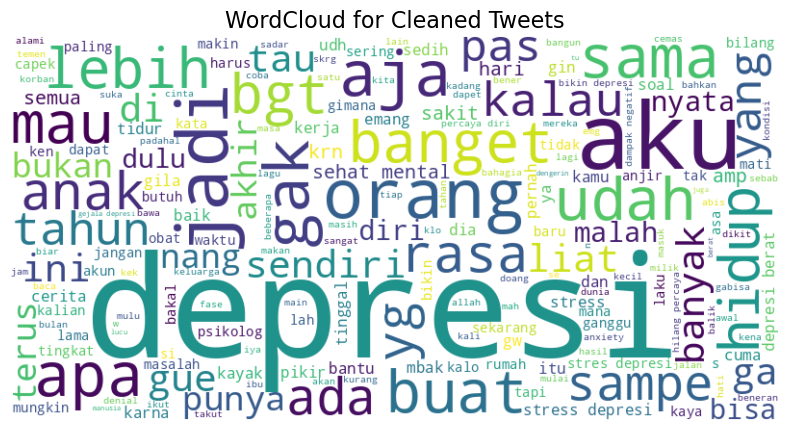

In [ ]:
all_words = ' '.join([text for text in df['stemmed_tweet']])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_words)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud for Cleaned Tweets', fontsize=16)
plt.show()

# Display final DataFrame

In [ ]:
df['stemmed_tweet'].head()

11    literally pingsan kmrn tidur jam sore bangun t...
37    maksud sender santai pikir bawa santai jangan ...
38                   oh jadi ini video anak depresi itu
39    fandom kalo snge brutal depresi brutal there s...
40                                        depresi lebih
Name: stemmed_tweet, dtype: object

In [ ]:
print(f"Final dataset size: {len(df)}")

Final dataset size: 1247
